#### Main Graph

In [1]:
"""Main LangGraph Workflow for IP-SAKTI Sahayak."""
from langgraph.graph import StateGraph, START, END
from core.state import GraphState
from nodes.guardrail import guardrail_assessor_node
from nodes.router import agentic_router_node
from nodes.query_rewriter import query_rewriter_node
from subgraphs.classifier_subgraph import create_formulation_subgraph
from nodes.generator import generator_node
from subgraphs.rag_subgraph import create_rag_subgraph
from core.checkpointer import get_checkpointer

# conditional edge routers
def route_guardrail(state: GraphState) -> str:
    """Conditional edge after guardrail assessment."""
    if not state.get("is_safe", True):
        return "generator"  # Early exit: safe abstention with zero token waste
    return "agentic_router"

def route_split(state: GraphState) -> str:
    """Conditional edge for the 3-way split."""
    route = state.get("route_path", "path_a")
    if route == "path_a":
        return "generator"
    elif route == "path_b":
        return "query_rewriter"
    elif route == "path_c":
        return "formulation_classifier"
    return "generator"

def build_graph() -> StateGraph:
    """Constructs and compiles the complete IP-SAKTI Sahayak LangGraph."""
    workflow = StateGraph(GraphState)

    # 1. Add Gatekeeper Nodes
    workflow.add_node("guardrail", guardrail_assessor_node)
    workflow.add_node("agentic_router", agentic_router_node)

    # 2. Add Branch Nodes & Subgraphs
    workflow.add_node("query_rewriter", query_rewriter_node)
    
    # Encapsulated Formulation Classifier Subgraph (Evaluator + HITL Pause)
    formulation_subgraph = create_formulation_subgraph()
    workflow.add_node("formulation_classifier", formulation_subgraph)

    # 3. Add RAG Subgraph & Generator
    rag_subgraph = create_rag_subgraph()
    workflow.add_node("rag_subgraph", rag_subgraph)
    workflow.add_node("generator", generator_node)

    # 4. Define Workflow Edges
    workflow.add_edge(START, "guardrail")

    workflow.add_conditional_edges(
        "guardrail",
        route_guardrail,
        {
            "generator": "generator",
            "agentic_router": "agentic_router"
        }
    )

    workflow.add_conditional_edges(
        "agentic_router",
        route_split,
        {
            "generator": "generator",
            "query_rewriter": "query_rewriter",
            "formulation_classifier": "formulation_classifier"
        }
    )

    workflow.add_edge("query_rewriter", "rag_subgraph")
    workflow.add_edge("formulation_classifier", "rag_subgraph")

    workflow.add_edge("rag_subgraph", "generator")
    workflow.add_edge("generator", END)

    # Compile with checkpointer for Human-In-The-Loop support
    # return workflow.compile(checkpointer=get_checkpointer())
    return workflow.compile()

# Precompiled instance
app = build_graph()


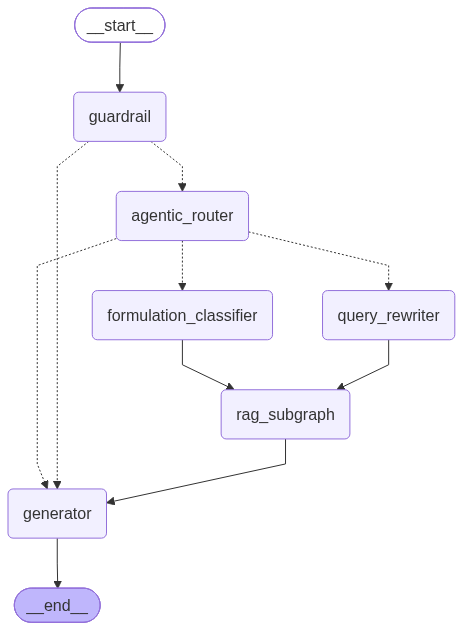

In [2]:
app

#### RAG SubGraph

In [ ]:
"""RAG Subgraph definition (Scatter-Gather Core)."""
from langgraph.graph import StateGraph, START, END
from core.state import GraphState
from nodes.rag.multi_source_router import multi_source_router_node
from nodes.rag.query_refiner import query_refiner_node
from nodes.rag.db_search import async_db_search_node
from nodes.rag.rag_eval import rag_eval_node
from nodes.rag.helper_injection import helper_injection_node

def create_rag_subgraph() -> StateGraph:
    """
    Builds the scatter-gather RAG Subgraph:
    Multi-Source Router -> Query Refiner -> Async DB Search -> RAG EVAL -> Helper Injection.
    """
    subgraph = StateGraph(GraphState)

    subgraph.add_node("multi_source_router", multi_source_router_node)
    subgraph.add_node("query_refiner", query_refiner_node)
    subgraph.add_node("async_db_search", async_db_search_node)
    subgraph.add_node("rag_eval", rag_eval_node)
    subgraph.add_node("helper_injection", helper_injection_node)

    subgraph.add_edge(START, "multi_source_router")
    subgraph.add_edge("multi_source_router", "query_refiner")
    subgraph.add_edge("query_refiner", "async_db_search")
    # rag_eval temporarily bypassed per user request to test direct generation
    subgraph.add_edge("async_db_search", "helper_injection")
    subgraph.add_edge("helper_injection", END)

    return subgraph.compile()


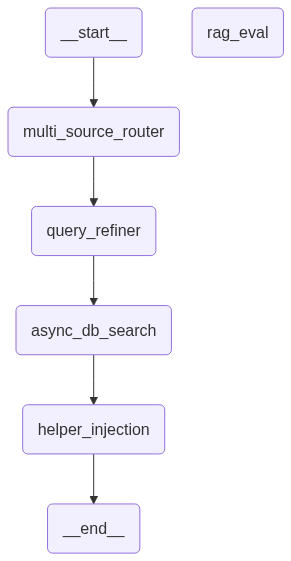

In [4]:
rag_subgraph = create_rag_subgraph()
rag_subgraph